
# FBI IC3 2025 — Reported Cybercrime Patterns in the United States

This notebook examines geographic differences in reported cybercrime across U.S. states, including complaint frequencies, crime categories, and financial losses. The analysis also considers differences across victim age groups and critical infrastructure sectors, relationships with state-level economic indicators, and the comparability of FBI IC3 findings with publicly documented cyber incidents.

**Data sources:** [FBI IC3 Annual Reports](https://www.ic3.gov/AnnualReport) |  [FBI IC3 2025 State Reports](https://www.ic3.gov/AnnualReport/Reports/2025State/)


In [26]:
# Libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from scipy.stats import pearsonr, spearmanr, norm, shapiro
from IPython.display import display

In [17]:
# Project paths
PROJECT_ROOT = Path("../..").resolve()

IC3_ANNUAL_DIR = PROJECT_ROOT / "data" / "processed" / "ic3" / "annual"
IC3_STATE_DIR = PROJECT_ROOT / "data" / "processed" / "ic3" / "state_reports"

FIGURES_DIR = PROJECT_ROOT / "figures" / "ic3"
STATIC_DIR = FIGURES_DIR / "static"
INTERACTIVE_DIR = FIGURES_DIR / "interactive"

STATIC_DIR.mkdir(parents=True, exist_ok=True)
INTERACTIVE_DIR.mkdir(parents=True, exist_ok=True)


# Processed analysis outputs
IC3_ANALYSIS_DIR = PROJECT_ROOT / "data" / "processed" / "ic3" / "analysis"
IC3_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# Annual Report datasets
ic3_state = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_state_2025.csv")
ic3_crime = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_crime_2025.csv")
ic3_crime_age = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_crime_age_2025.csv")
ic3_sector = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_sector_2025.csv")
ic3_ai = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_ai_2025.csv")
ic3_crypto = pd.read_csv(IC3_ANNUAL_DIR / "fbi_ic3_national_crypto_2025.csv")

In [4]:
# State Reports datasets
ic3_state_crime = pd.read_csv(IC3_STATE_DIR / "fbi_ic3_state_crime_2025.csv")
ic3_state_age = pd.read_csv(IC3_STATE_DIR / "fbi_ic3_state_age_2025.csv")

In [5]:
# Dataset registry
ic3_datasets = {
    "State overview": ic3_state,
    "National crime": ic3_crime,
    "National crime by age": ic3_crime_age,
    "Critical infrastructure": ic3_sector,
    "AI-related crime": ic3_ai,
    "Cryptocurrency-related crime": ic3_crypto,
    "State crime": ic3_state_crime,
    "State age": ic3_state_age,
}

In [6]:
print(f"Project root: {PROJECT_ROOT}")
print(f"Successfully loaded {len(ic3_datasets)} FBI IC3 datasets.")


Project root: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa
Successfully loaded 8 FBI IC3 datasets.


In [7]:
# Economic factors and UMD data
ECONOMIC_DIR = PROJECT_ROOT / "data" / "processed" / "economic" / "combined"
UMD_DIR = PROJECT_ROOT / "data" / "processed" / "umd_usa"

economic_factors = pd.read_csv(
    ECONOMIC_DIR / "usa_state_economic_factors_2014_2025.csv"
)

umd_incidents_economic = pd.read_csv(
    ECONOMIC_DIR / "usa_state_incidents_economic_2014_2025.csv"
)

umd_incidents = pd.read_csv(
    UMD_DIR / "umd_usa_deduplicated_consolidated.csv"
)

print("Economic factors and UMD datasets loaded successfully.")


Economic factors and UMD datasets loaded successfully.



## 1. Data Sources and Coverage

The analysis uses eight datasets extracted from the FBI Internet Crime Complaint Center (IC3) 2025 Annual Report and the corresponding State Reports. These datasets provide state-level and national statistics on reported cybercrime, including complaint counts, financial losses, crime categories, victim age groups, and selected critical infrastructure sectors.

The Annual Report and State Reports are treated as distinct sources because their reported figures and classifications are not necessarily identical. FBI IC3 complaints are also distinguished from publicly documented cyber incidents, which are recorded using different collection criteria.



### 1.1 Dataset Inventory

Eight datasets extracted from the FBI IC3 2025 Annual Report and State Reports form the basis of the analysis. The datasets contain information at different levels of aggregation, including U.S. states, crime categories, victim age groups, and critical infrastructure sectors.

The inventory below summarizes the size, structure, and source of each dataset.



In [8]:
# Dataset inventory
dataset_sources = {
    "State overview": "Annual Report",
    "National crime": "Annual Report",
    "National crime by age": "Annual Report",
    "Critical infrastructure": "Annual Report",
    "AI-related crime": "Annual Report",
    "Cryptocurrency-related crime": "Annual Report",
    "State crime": "State Reports",
    "State age": "State Reports",
}

dataset_inventory = pd.DataFrame([
    {
        "Dataset": name,
        "Source": dataset_sources[name],
        "Rows": len(df),
        "Columns": df.shape[1],
        "Missing values": int(df.isna().sum().sum()),
    }
    for name, df in ic3_datasets.items()
])

display(dataset_inventory)


,Dataset,Source,Rows,Columns,Missing values
0,State overview,Annual Report,51,12,0
1,National crime,Annual Report,29,8,0
2,National crime by age,Annual Report,156,9,130
3,Critical infrastructure,Annual Report,16,7,0
4,AI-related crime,Annual Report,28,8,0
5,Cryptocurrency-related crime,Annual Report,28,8,0
6,State crime,State Reports,1581,9,0
7,State age,State Reports,306,6,0



## 2. Data Quality and Descriptive Overview

The datasets are assessed for completeness, duplicate records, missing values, category consistency, and numerical anomalies. Their geographic coverage, measurement units, and differences in classification are examined to establish which comparisons are appropriate.

Missing-value distributions and dataset characteristics are presented visually, while identified limitations are retained in the interpretation of subsequent results.



### 2.1 Missing Values

Only three numerical values are missing across the eight datasets, all in the national crime-by-age dataset. The remaining missing entries belong to an optional quality-note field and do not represent missing measurements.


In [9]:
# Missing values by column
missing_details = pd.DataFrame([
    {
        "Dataset": name,
        "Column": column,
        "Missing": int(count),
        "Missing (%)": round(count / len(df) * 100, 2),
    }
    for name, df in ic3_datasets.items()
    for column, count in df.isna().sum().items()
    if count > 0
])

display(missing_details)


,Dataset,Column,Missing,Missing (%)
0,National crime by age,loss_usd,3,1.92
1,National crime by age,quality_note,127,81.41


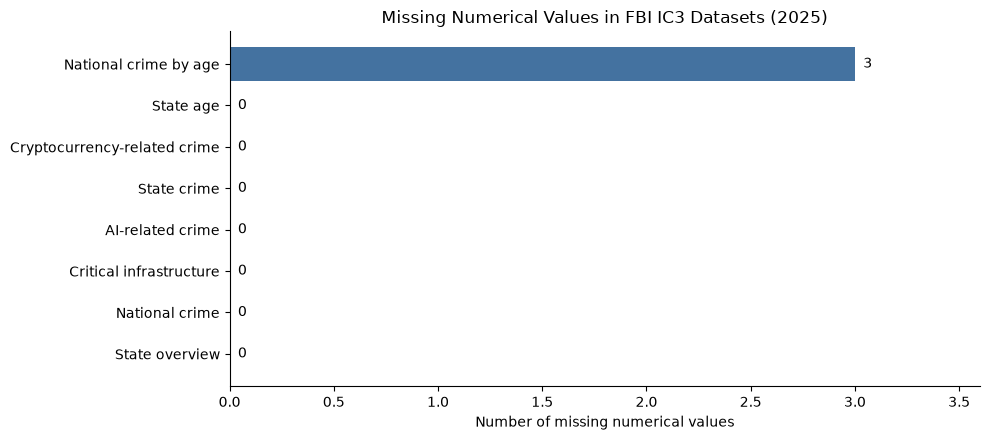

In [10]:
# Missing measurements by dataset
missing_numeric = pd.Series({
    name: int(df.select_dtypes(include="number").isna().sum().sum())
    for name, df in ic3_datasets.items()
}).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 4.5))

bars = ax.barh(
    missing_numeric.index,
    missing_numeric.values,
    color="#4472A0"
)

for bar, value in zip(bars, missing_numeric.values):
    ax.text(
        value + 0.04,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontsize=10
    )

ax.set_xlim(0, max(missing_numeric.max() * 1.2, 1))
ax.set_xlabel("Number of missing numerical values")
ax.set_title("Missing Numerical Values in FBI IC3 Datasets (2025)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(STATIC_DIR / "02_01_missing_values.png", dpi=300, bbox_inches="tight")
plt.show()



### 2.2 Data Consistency

Dataset consistency is assessed using the expected unique identifiers, duplicate records, and negative numerical values. These checks help identify structural errors before the analysis of reported cybercrime patterns.


In [11]:
# Expected unique identifiers for each dataset
dataset_keys = {
    "State overview": ["state", "year"],
    "National crime": ["year", "crime_type"],
    "National crime by age": ["year", "crime_type", "age_group"],
    "Critical infrastructure": ["sector"],
    "AI-related crime": ["year", "crime_type"],
    "Cryptocurrency-related crime": ["year", "crime_type"],
    "State crime": ["state", "year", "category"],
    "State age": ["state", "year", "age_group"],
}


consistency_results = []

for name, df in ic3_datasets.items():
    keys = dataset_keys[name]
    missing_keys = [key for key in keys if key not in df.columns]

    duplicate_rows = df.duplicated().sum()
    duplicate_keys = (
        df.duplicated(subset=keys).sum()
        if not missing_keys else np.nan
    )

    numeric_columns = df.select_dtypes(include="number").drop(
        columns=["year"], errors="ignore"
    )
    negative_values = (numeric_columns < 0).sum().sum()

    consistency_results.append({
        "Dataset": name,
        "Duplicate rows": int(duplicate_rows),
        "Duplicate keys": duplicate_keys,
        "Negative values": int(negative_values),
        "Missing key columns": ", ".join(missing_keys) if missing_keys else "None",
    })

consistency_summary = pd.DataFrame(consistency_results)
display(consistency_summary)


,Dataset,Duplicate rows,Duplicate keys,Negative values,Missing key columns
0,State overview,0,0,0,None
1,National crime,0,0,0,None
2,National crime by age,0,0,0,None
3,Critical infrastructure,0,0,0,None
4,AI-related crime,0,0,0,None
5,Cryptocurrency-related crime,0,0,0,None
6,State crime,0,0,0,None
7,State age,0,0,0,None



## 3. Research Questions and Visual Analysis

The analysis focuses on geographic differences, the distribution of reported cybercrime, and its financial consequences. Each research question is examined using appropriate statistical summaries and visualizations, with emphasis on patterns relevant to differences between states, economic characteristics, and potential cybersecurity priorities.


### 3.1 Which states stand out in reported complaints and financial losses?

State-level complaint rates and financial losses per 100,000 residents are compared to identify the states that stand out in reported cybercrime frequency and financial impact.

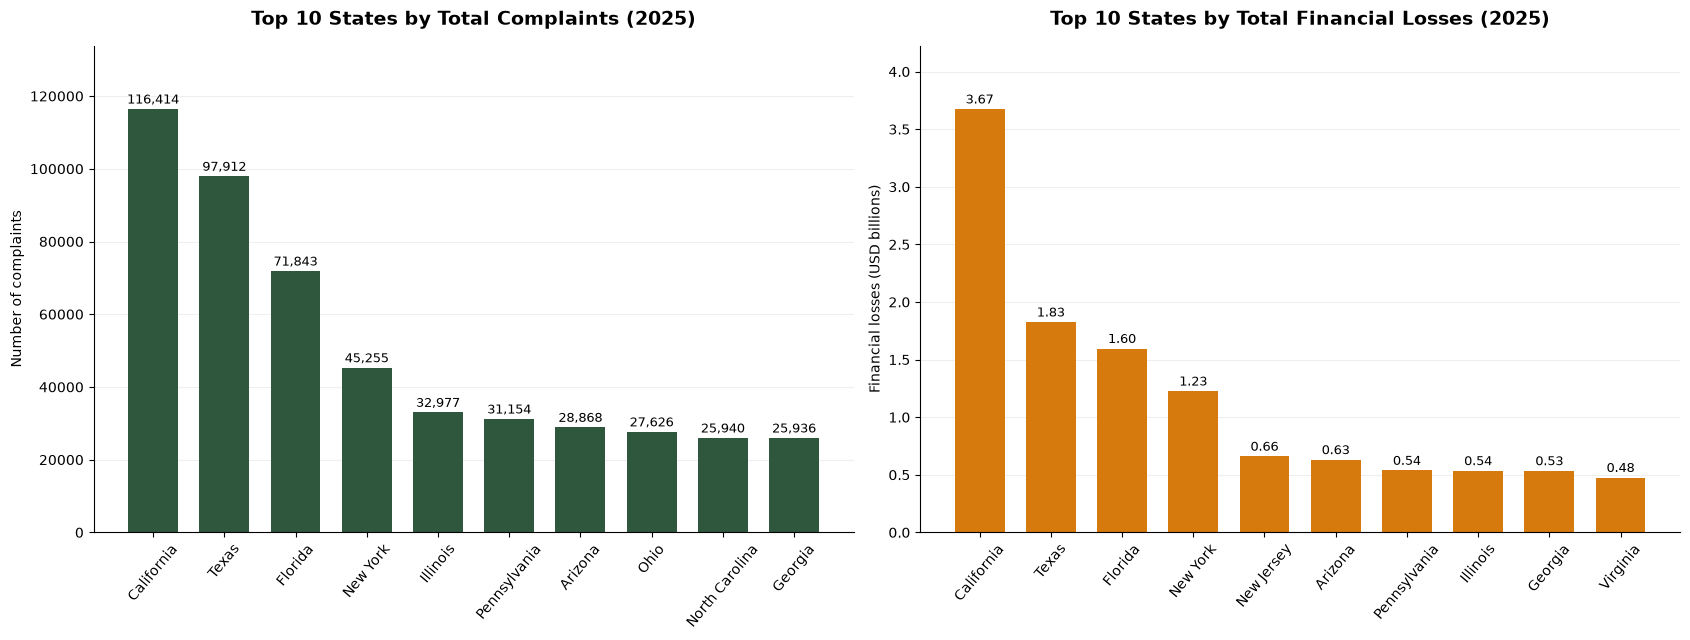

In [14]:
# Top 10 states by absolute complaints and financial losses
top_complaints_abs = ic3_state.nlargest(10, "complaints")
top_losses_abs = ic3_state.nlargest(10, "loss_usd").copy()
top_losses_abs["loss_billion"] = top_losses_abs["loss_usd"] / 1_000_000_000

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Total complaints
bars = axes[0].bar(
    top_complaints_abs["state"],
    top_complaints_abs["complaints"],
    color="#2F573E",
    width=0.7
)

axes[0].set_title(
    "Top 10 States by Total Complaints (2025)",
    fontsize=14, fontweight="bold", pad=15
)
axes[0].set_ylabel("Number of complaints")

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", fontsize=9
    )

# Total financial losses
bars = axes[1].bar(
    top_losses_abs["state"],
    top_losses_abs["loss_billion"],
    color="#D67A0D",
    width=0.7
)

axes[1].set_title(
    "Top 10 States by Total Financial Losses (2025)",
    fontsize=14, fontweight="bold", pad=15
)
axes[1].set_ylabel("Financial losses (USD billions)")

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:,.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", fontsize=9
    )

for ax in axes:
    ax.tick_params(axis="x", rotation=50)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

plt.tight_layout()
plt.savefig(
    STATIC_DIR / "03_02_top_states_absolute_2025.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


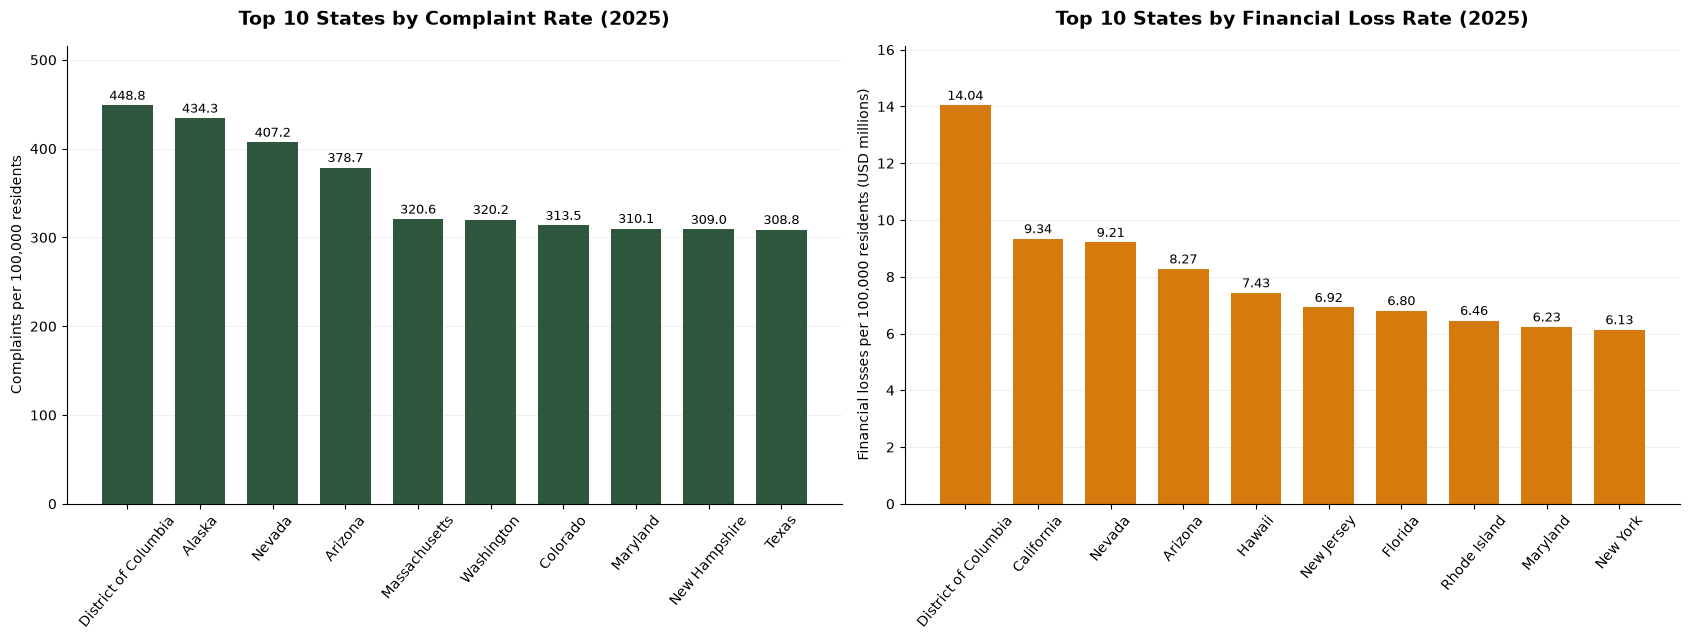

In [15]:

# Top 10 states by normalized complaints and financial losses
top_complaints = ic3_state.nlargest(10, "complaints_per_100k")
top_losses = ic3_state.nlargest(10, "loss_per_100k_usd").copy()
top_losses["loss_million"] = top_losses["loss_per_100k_usd"] / 1_000_000

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

colors = ["#2F573E", "#D67A0D"]

# Complaints per 100,000 residents
bars = axes[0].bar(
    top_complaints["state"],
    top_complaints["complaints_per_100k"],
    color=colors[0],
    width=0.7
)

axes[0].set_title(
    "Top 10 States by Complaint Rate (2025)",
    fontsize=14, fontweight="bold", pad=15
)
axes[0].set_ylabel("Complaints per 100,000 residents")

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(
        f"{height:,.1f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", fontsize=9
    )

# Financial losses per 100,000 residents
bars = axes[1].bar(
    top_losses["state"],
    top_losses["loss_million"],
    color=colors[1],
    width=0.7
)

axes[1].set_title(
    "Top 10 States by Financial Loss Rate (2025)",
    fontsize=14, fontweight="bold", pad=15
)
axes[1].set_ylabel("Financial losses per 100,000 residents (USD millions)")

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:,.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", fontsize=9
    )

for ax in axes:
    ax.tick_params(axis="x", rotation=50)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

plt.tight_layout()
plt.savefig(
    STATIC_DIR / "03_01_top_states_normalized_2025.png",
    dpi=300, bbox_inches="tight"
)
plt.show()



### 3.2 Do states differ in the composition of reported cybercrime?

The distribution of reported crime categories is examined across states to identify differences in the composition of complaints and associated financial losses.


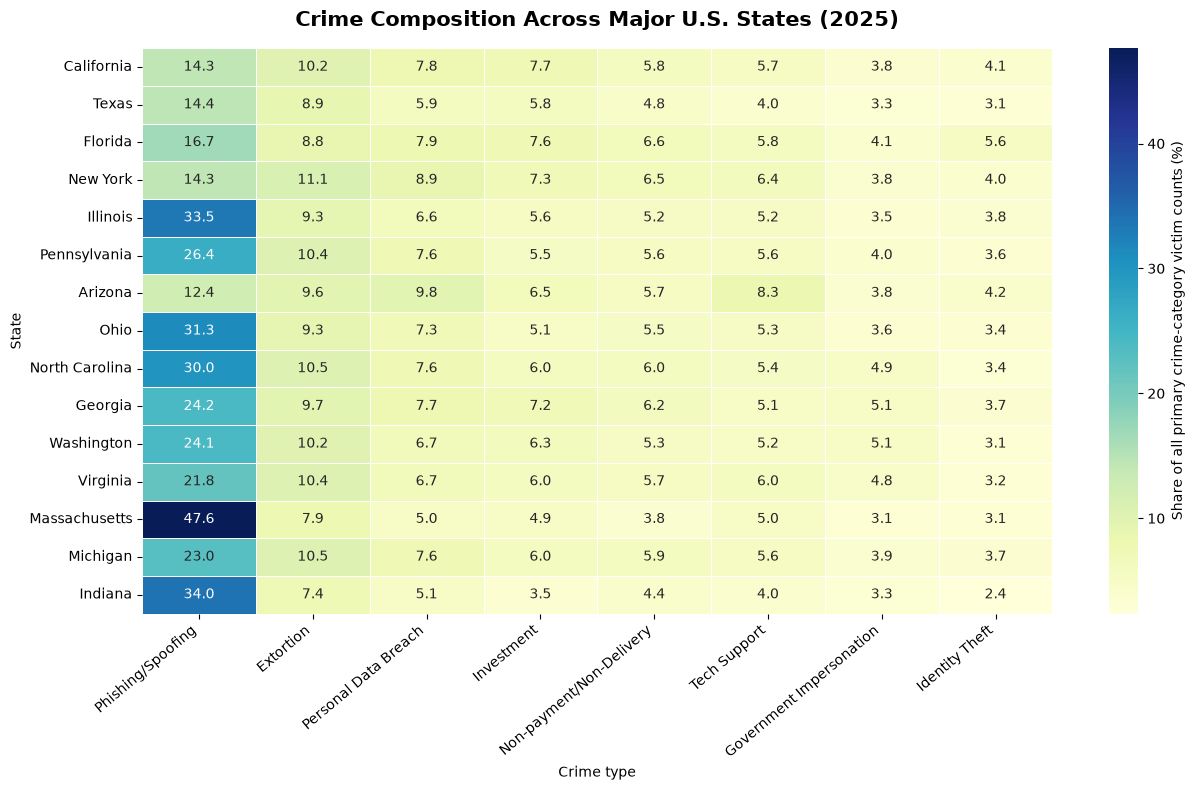

In [19]:

# Crime composition across the 15 states with most complaints

# Include all primary crime categories in the denominator
crime_data = ic3_state_crime[
    ic3_state_crime["category_kind"] == "crime_type"
].copy()

top_states = (
    ic3_state.nlargest(15, "complaints")["state"].tolist()
)

# Select the eight most common substantive crime categories
top_categories = (
    crime_data[
        ~crime_data["category"].isin(["No Lead Value", "Other"])
    ]
    .groupby("category")["victim_count"]
    .sum()
    .nlargest(8)
    .index.tolist()
)

# State-by-crime matrix for all primary categories
crime_matrix = crime_data.pivot_table(
    index="state",
    columns="category",
    values="victim_count",
    aggfunc="sum",
    fill_value=0
)

# Calculate shares using all primary category counts
crime_shares = crime_matrix.div(
    crime_matrix.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

# Display only the selected categories and states
heatmap_shares = crime_shares.loc[top_states, top_categories]

# Export the data behind the visualization
heatmap_shares.to_csv(
    IC3_ANALYSIS_DIR / "03_02_state_crime_composition_shares_2025.csv"
)

# Visualization
fig, ax = plt.subplots(figsize=(13, 8))

sns.heatmap(
    heatmap_shares,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Share of all primary crime-category victim counts (%)"},
    ax=ax
)

ax.set_title(
    "Crime Composition Across Major U.S. States (2025)",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Crime type")
ax.set_ylabel("State")

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_03_state_crime_composition_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 3.3 How do complaint and financial loss patterns differ across victim age groups?

Complaint frequencies and reported financial losses are examined across age groups to identify differences in victimization patterns and financial impact.


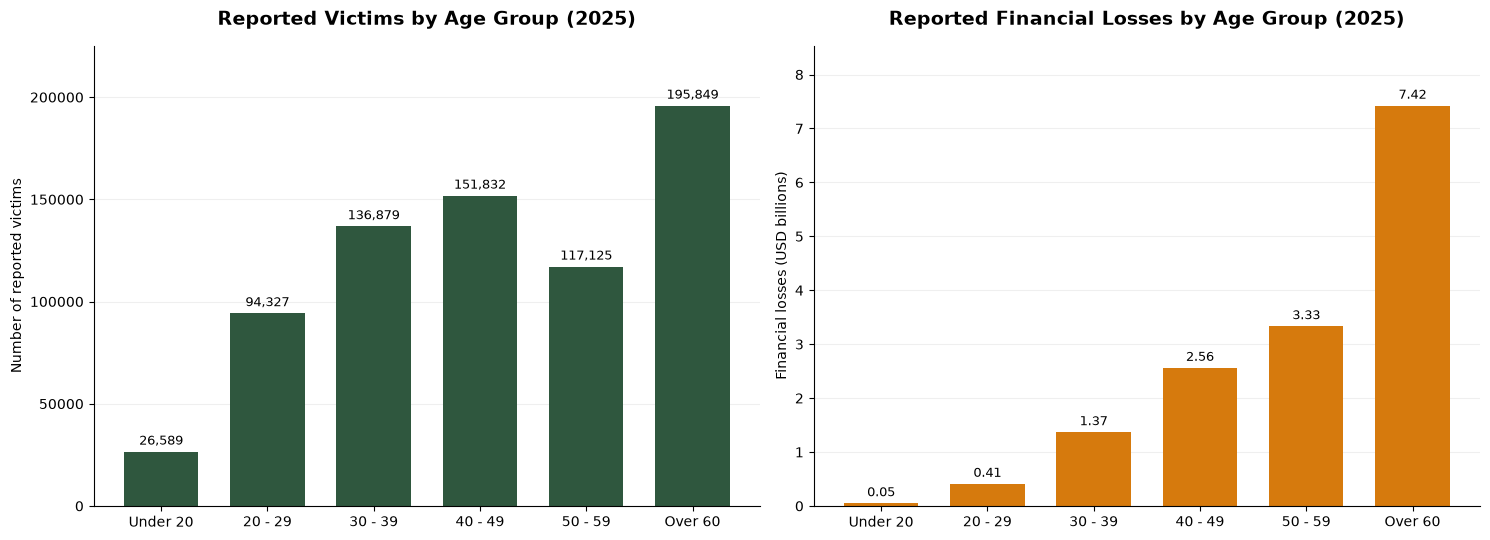

In [ ]:
# Aggregate victims and financial losses across states
age_order = [
    "Under 20", "20 - 29", "30 - 39",
    "40 - 49", "50 - 59", "Over 60"
]

age_summary = (
    ic3_state_age.groupby("age_group", as_index=False)
    .agg(
        victims=("victim_count", "sum"),
        loss_usd=("victim_loss_usd", "sum")
    )
    .set_index("age_group")
    .reindex(age_order)
    .reset_index()
)

age_summary["loss_billion"] = age_summary["loss_usd"] / 1e9

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Number of victims
bars = axes[0].bar(
    age_summary["age_group"],
    age_summary["victims"],
    color="#2F573E",
    width=0.7
)

axes[0].set_title(
    "Reported Victims by Age Group (2025)",
    fontsize=14, fontweight="bold", pad=15
)
axes[0].set_ylabel("Number of reported victims")

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", fontsize=9
    )

# Financial losses
bars = axes[1].bar(
    age_summary["age_group"],
    age_summary["loss_billion"],
    color="#D67A0D",
    width=0.7
)

axes[1].set_title(
    "Reported Financial Losses by Age Group (2025)",
    fontsize=14, fontweight="bold", pad=15
)
axes[1].set_ylabel("Financial losses (USD billions)")

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:.2f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", fontsize=9
    )

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_05_victims_losses_by_age_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 3.4 Which critical infrastructure sectors stand out in reported cybercrime?

The FBI IC3 2025 Annual Report provides sector-level complaint counts for Ransomware and Data Breach across 16 critical infrastructure sectors. These are the only two crime categories with available sector-level breakdowns.

The analysis compares their distribution across sectors and examines their combined reported volume. The combined figures represent the sum of the two category counts, not necessarily unique incidents.


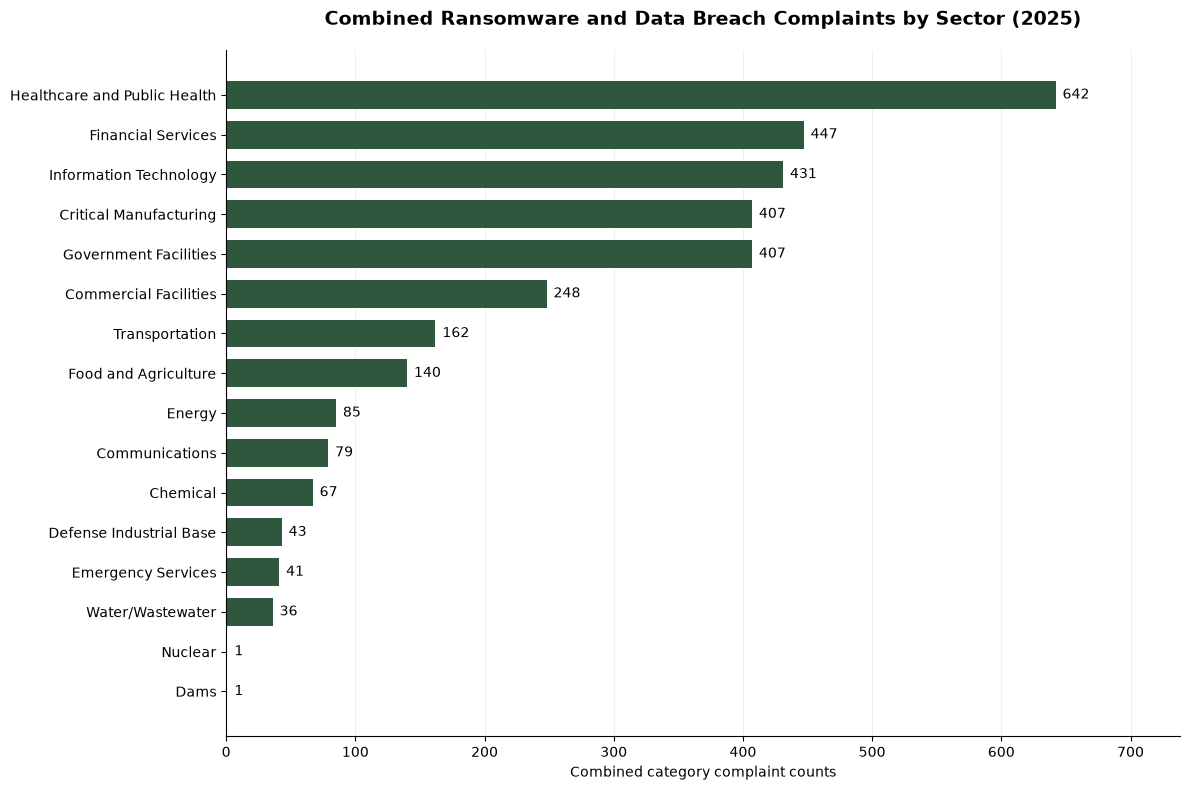

In [23]:
# Combined ransomware and data breach complaint counts by sector
sector_totals = ic3_sector.copy()

sector_totals["combined_complaints"] = (
    sector_totals["ransomware_complaints"]
    + sector_totals["data_breach_complaints"]
)

sector_totals = sector_totals.sort_values(
    "combined_complaints", ascending=True
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    sector_totals["sector"],
    sector_totals["combined_complaints"],
    color="#2F573E",
    height=0.7
)

for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:,.0f}",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Combined Ransomware and Data Breach Complaints by Sector (2025)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Combined category complaint counts")
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.set_xlim(0, sector_totals["combined_complaints"].max() * 1.15)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_07_combined_sector_complaints_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


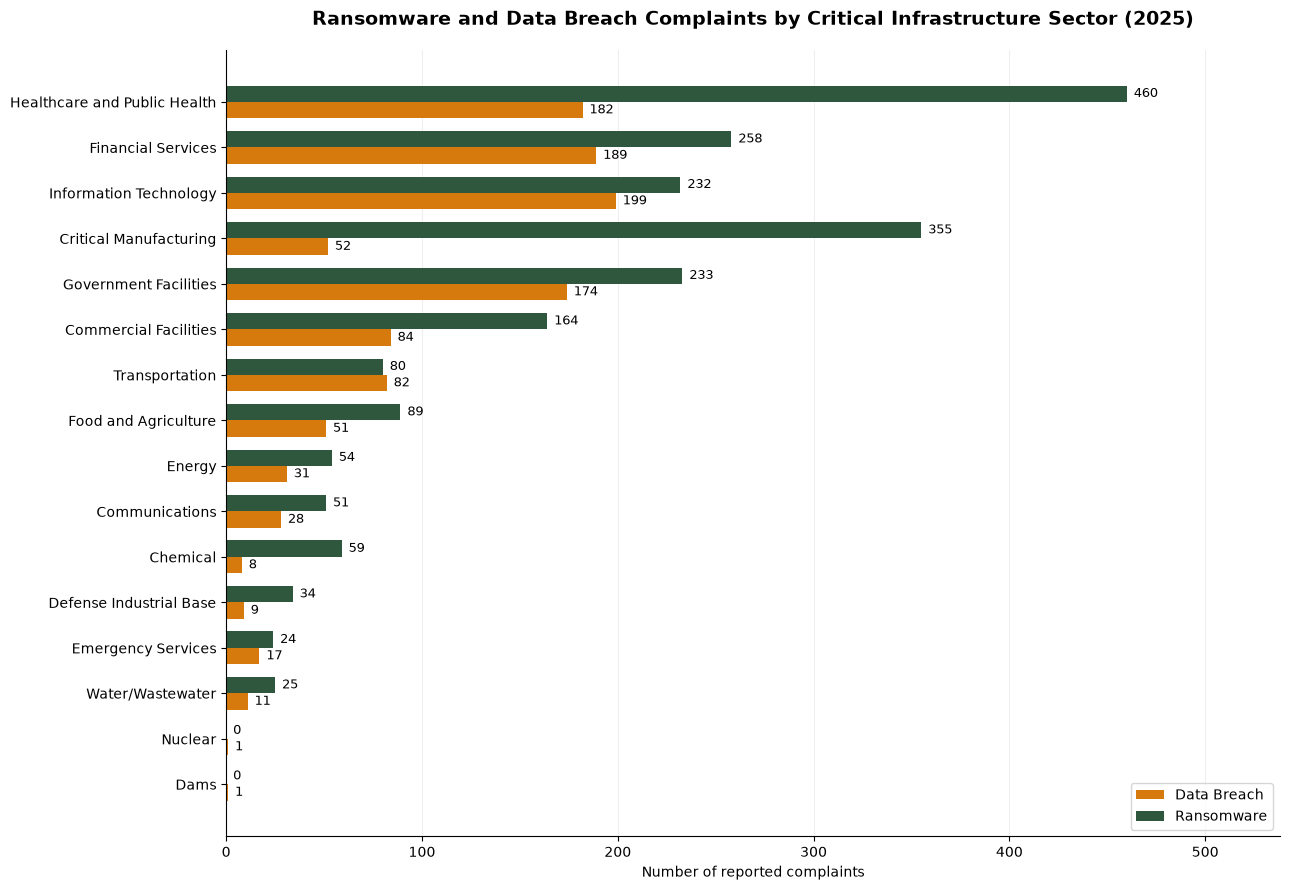

In [22]:
# Critical infrastructure complaints by sector
sector_data = ic3_sector.copy()

sector_data["total_complaints"] = (
    sector_data["ransomware_complaints"]
    + sector_data["data_breach_complaints"]
)

sector_data = sector_data.sort_values(
    "total_complaints", ascending=True
)

fig, ax = plt.subplots(figsize=(13, 9))

y = np.arange(len(sector_data))
bar_height = 0.36

# Data breach complaints
bars_breach = ax.barh(
    y - bar_height / 2,
    sector_data["data_breach_complaints"],
    height=bar_height,
    color="#D67A0D",
    label="Data Breach"
)

# Ransomware complaints
bars_ransomware = ax.barh(
    y + bar_height / 2,
    sector_data["ransomware_complaints"],
    height=bar_height,
    color="#2F573E",
    label="Ransomware"
)

# Value labels
for bars in [bars_breach, bars_ransomware]:
    for bar in bars:
        width = bar.get_width()
        ax.annotate(
            f"{width:,.0f}",
            (width, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

ax.set_yticks(y)
ax.set_yticklabels(sector_data["sector"])

ax.set_xlabel("Number of reported complaints")
ax.set_ylabel("")
ax.set_title(
    "Ransomware and Data Breach Complaints by Critical Infrastructure Sector (2025)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.legend(loc="lower right", frameon=True)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(
    0,
    max(
        sector_data["ransomware_complaints"].max(),
        sector_data["data_breach_complaints"].max()
    ) * 1.17
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_06_critical_infrastructure_complaints_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 3.5 Are reported cybercrime patterns associated with state-level economic factors?

FBI IC3 complaint rates are examined in relation to the same seven economic indicators used in the UMD analysis. The comparison covers the 50 U.S. states in 2025 and follows the same normalization, correlation methods, and statistical significance criteria.


In [24]:
# Prepare the 2025 economic data for the 50 U.S. states
economic_2025 = economic_factors.loc[
    economic_factors["year"] == 2025
].copy()

# Use the same states and year as the economic dataset
ic3_2025 = ic3_state.loc[
    ic3_state["year"] == 2025
].copy()

# Merge FBI IC3 with economic factors
ic3_economic = economic_2025.merge(
    ic3_2025,
    on=["state", "year"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify state coverage and completeness
print(f"Economic states: {len(economic_2025)}")
print(f"Matched states: {(ic3_economic['_merge'] == 'both').sum()}")
print(f"Unmatched states: {(ic3_economic['_merge'] != 'both').sum()}")

economic_features = {
    "gdp_per_capita": "GDP per capita",
    "personal_income_per_capita": "Personal income per capita",
    "real_gdp_growth_pct": "Real GDP growth",
    "unemployment_rate": "Unemployment rate",
    "labor_force_participation_rate": "Labor force participation",
    "establishments_per_10k": "Establishment density",
    "qcew_avg_annual_pay": "Average annual pay"
}

required_columns = list(economic_features) + ["complaints_per_100k"]

print("\nMissing values by variable:")
print(ic3_economic[required_columns].isna().sum().to_string())

# Keep only matched states
ic3_economic = (
    ic3_economic.loc[ic3_economic["_merge"] == "both"]
    .drop(columns="_merge")
    .copy()
)

display(
    ic3_economic[
        ["state", "year", "complaints_per_100k"]
        + list(economic_features)
    ].head()
)


Economic states: 50
Matched states: 50
Unmatched states: 0

Missing values by variable:
gdp_per_capita                    0
personal_income_per_capita        0
real_gdp_growth_pct               0
unemployment_rate                 0
labor_force_participation_rate    0
establishments_per_10k            0
qcew_avg_annual_pay               0
complaints_per_100k               0


,state,year,complaints_per_100k,gdp_per_capita,personal_income_per_capita,real_gdp_growth_pct,unemployment_rate,labor_force_participation_rate,establishments_per_10k,qcew_avg_annual_pay
0,Alabama,2025,191.3,65285.837636,59754.0,1.979556,2.9,57.6,316.156784,64479
1,Alaska,2025,434.3,99874.944050,80510.0,4.749473,4.7,65.7,341.381041,75391
2,Arizona,2025,378.7,77664.891790,68373.0,1.457001,4.3,62.1,296.356760,72894
3,Arkansas,2025,197.8,62921.781911,61697.0,0.931189,4.1,58.7,353.076659,61152
4,California,2025,295.8,109196.190024,90957.0,3.537275,5.5,62.4,476.976562,96963


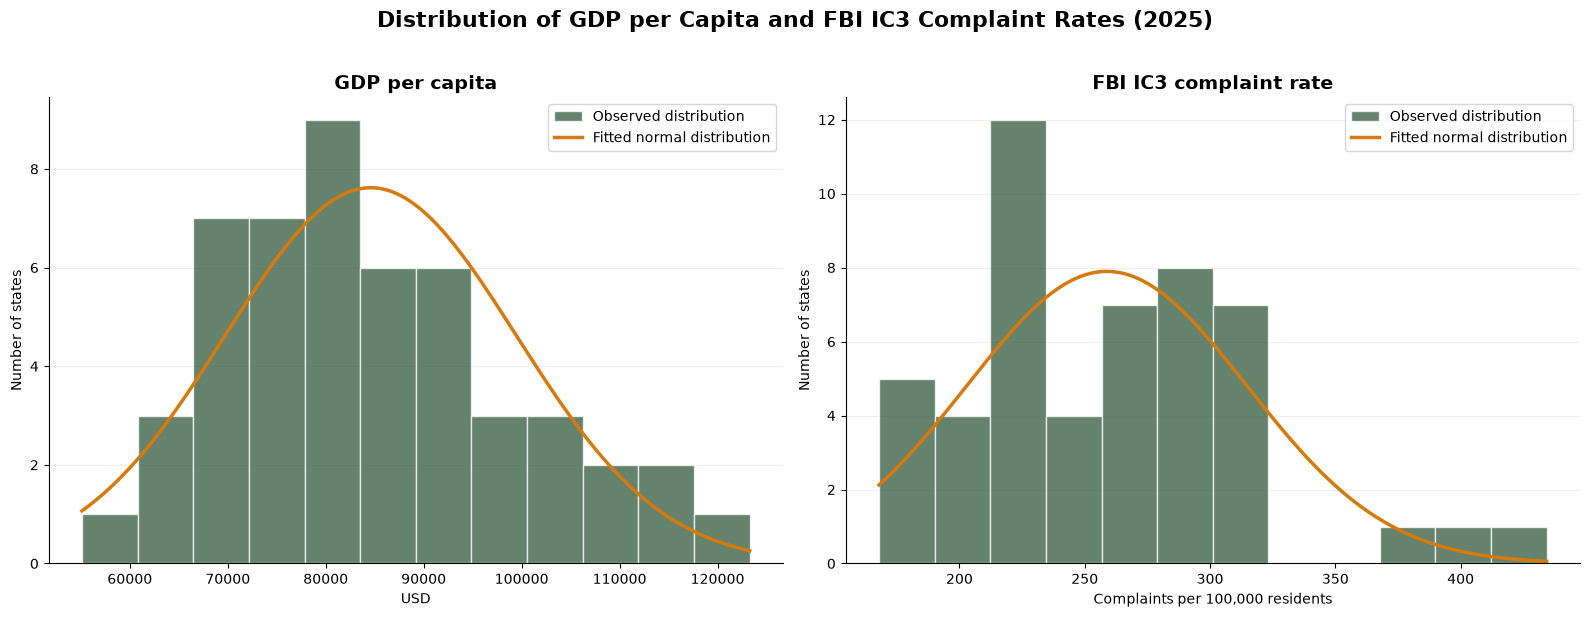

In [ ]:
# Distribution assessment for FBI IC3 and GDP per capita (2025)
variables = [
    ("gdp_per_capita", "GDP per capita", "USD"),
    ("complaints_per_100k", "FBI IC3 complaint rate",
     "Complaints per 100,000 residents")
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (column, title, xlabel) in zip(axes, variables):
    values = ic3_economic[column].dropna().to_numpy()
    n_bins = 12

    counts, edges, _ = ax.hist(
        values,
        bins=n_bins,
        color="#31583B",
        alpha=0.75,
        edgecolor="white",
        label="Observed distribution"
    )

    # Fitted normal distribution scaled to histogram counts
    mu, sigma = norm.fit(values)
    x = np.linspace(values.min(), values.max(), 300)
    bin_width = edges[1] - edges[0]

    expected = norm.pdf(x, mu, sigma) * len(values) * bin_width

    ax.plot(
        x, expected,
        color="#D67A0D",
        linewidth=2.5,
        label="Fitted normal distribution"
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of states")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()

fig.suptitle(
    "Distribution of GDP per Capita and FBI IC3 Complaint Rates (2025)",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_08_fbi_economic_distributions_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Normality assessment**

The Shapiro–Wilk test is applied to GDP per capita and FBI IC3 complaint rates across the 50 states. The test evaluates whether each variable significantly deviates from a normal distribution at the 5% significance level.


In [27]:
# Shapiro–Wilk normality tests
normality_results = []

for column, label in [
    ("gdp_per_capita", "GDP per capita"),
    ("complaints_per_100k", "FBI IC3 complaint rate")
]:
    values = ic3_economic[column].dropna()
    statistic, p_value = shapiro(values)

    normality_results.append({
        "Variable": label,
        "W statistic": round(statistic, 4),
        "p-value": round(p_value, 6),
        "Normality (α = 0.05)": (
            "Not rejected" if p_value >= 0.05 else "Rejected"
        )
    })

normality_summary = pd.DataFrame(normality_results)
display(normality_summary)


,Variable,W statistic,p-value,Normality (α = 0.05)
0,GDP per capita,0.9723,0.287226,Not rejected
1,FBI IC3 complaint rate,0.9424,0.016725,Rejected


**Statistical method**

The Shapiro–Wilk test did not reject normality for GDP per capita (p = 0.2872), while the FBI IC3 complaint rate showed a statistically significant deviation from normality (p = 0.0167).

Spearman's rank correlation is used to assess associations between FBI IC3 complaint rates and seven economic indicators across 50 U.S. states in 2025.

To account for multiple hypothesis testing, the Benjamini–Hochberg (BH) procedure is applied with a false discovery rate (FDR) of 5%. Both original and adjusted p-values are reported, while statistical significance is determined using the adjusted values.


In [29]:
# Spearman correlations between economic factors and FBI IC3 complaint rates
spearman_results = []

for column, label in economic_features.items():
    data = ic3_economic[
        [column, "complaints_per_100k"]
    ].dropna()

    rho, p_value = spearmanr(
        data[column],
        data["complaints_per_100k"]
    )

    spearman_results.append({
        "Economic factor": label,
        "Spearman rho": rho,
        "p-value": p_value,
        "Significant (p < 0.05)": p_value < 0.05
    })

spearman_summary = (
    pd.DataFrame(spearman_results)
    .sort_values("Spearman rho", ascending=False)
    .reset_index(drop=True)
)


# Display correlation results
display(
    spearman_summary.round({
        "Spearman rho": 3,
        "p-value": 4
    })
)



,Economic factor,Spearman rho,p-value,Significant (p < 0.05)
0,Average annual pay,0.486,0.0003,True
1,Personal income per capita,0.425,0.0021,True
2,GDP per capita,0.379,0.0067,True
3,Unemployment rate,0.279,0.0498,True
4,Labor force participation,0.275,0.0529,False
5,Real GDP growth,0.247,0.0838,False
6,Establishment density,-0.059,0.6854,False



**Key findings**

Spearman's correlation analysis identifies positive associations between FBI IC3 complaint rates and average annual pay (ρ = 0.486, p = 0.0003), personal income per capita (ρ = 0.425, p = 0.0021), and GDP per capita (ρ = 0.379, p = 0.0067).

Unemployment shows a weaker, marginally significant association (ρ = 0.279, p = 0.0498). The remaining indicators do not show statistically significant relationships at the 5% level.

The three strongest associations also remain significant under Bonferroni correction for seven tests. These results indicate economic associations rather than causal effects.



**Statistical methodology**

Spearman's rank correlation is used to assess associations between FBI IC3 complaint rates and seven economic indicators across 50 U.S. states in 2025.

To account for multiple hypothesis testing, the Benjamini–Hochberg (BH) procedure is applied with a false discovery rate (FDR) of 5%. Both original and adjusted p-values are reported, while statistical significance is determined using the adjusted values.

The analysis is exploratory, and the identified associations do not imply causality.


In [31]:
# Benjamini-Hochberg correction for multiple testing
p_values = spearman_summary["p-value"].to_numpy()
m = len(p_values)

order = np.argsort(p_values)
ranked_p = p_values[order]

adjusted = ranked_p * m / np.arange(1, m + 1)
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
adjusted = np.clip(adjusted, 0, 1)

bh_p_values = np.empty(m)
bh_p_values[order] = adjusted

spearman_summary["BH-adjusted p-value"] = bh_p_values
spearman_summary["BH significant (FDR < 0.05)"] = (
    bh_p_values < 0.05
)

display(
    spearman_summary.round({
        "Spearman rho": 3,
        "p-value": 4,
        "BH-adjusted p-value": 4
    })
)


,Economic factor,Spearman rho,p-value,Significant (p < 0.05),BH-adjusted p-value,BH significant (FDR < 0.05)
0,Average annual pay,0.486,0.0003,True,0.0024,True
1,Personal income per capita,0.425,0.0021,True,0.0074,True
2,GDP per capita,0.379,0.0067,True,0.0157,True
3,Unemployment rate,0.279,0.0498,True,0.0741,False
4,Labor force participation,0.275,0.0529,False,0.0741,False
5,Real GDP growth,0.247,0.0838,False,0.0978,False
6,Establishment density,-0.059,0.6854,False,0.6854,False


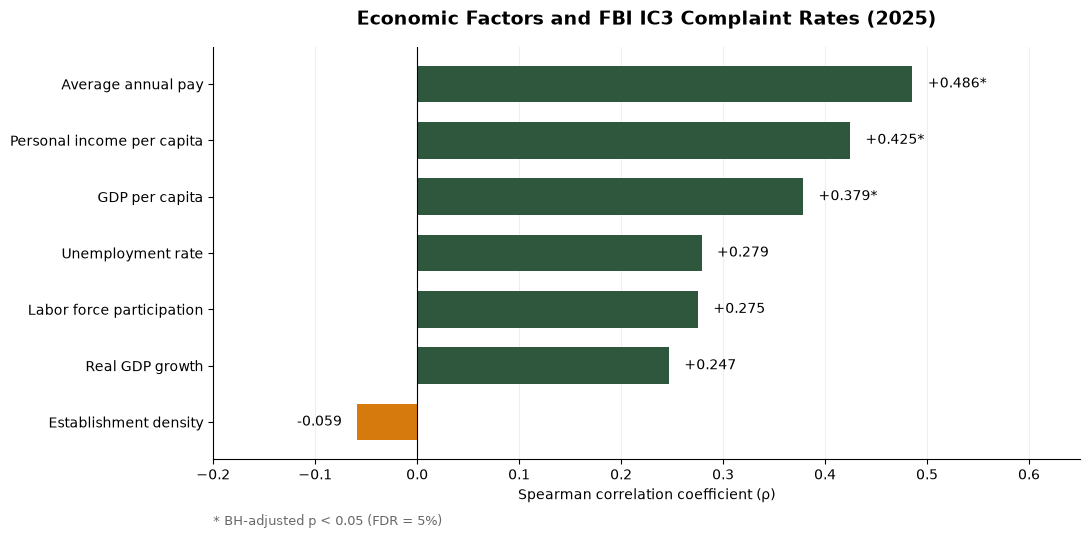

In [33]:
# Spearman correlations: FBI IC3 complaint rates and economic factors
plot_data = spearman_summary.sort_values("Spearman rho").copy()

colors = [
    "#2F573E" if rho >= 0 else "#D67A0D"
    for rho in plot_data["Spearman rho"]
]

fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.barh(
    plot_data["Economic factor"],
    plot_data["Spearman rho"],
    color=colors,
    height=0.65
)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    rho = row["Spearman rho"]
    marker = "*" if row["BH significant (FDR < 0.05)"] else ""
    offset = 0.015 if rho >= 0 else -0.015

    ax.text(
        rho + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{rho:+.3f}{marker}",
        va="center",
        ha="left" if rho >= 0 else "right",
        fontsize=10
    )

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.20, 0.65)
ax.set_xlabel("Spearman correlation coefficient (ρ)")
ax.set_title(
    "Economic Factors and FBI IC3 Complaint Rates (2025)",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.text(
    0, -0.16,
    "* BH-adjusted p < 0.05 (FDR = 5%)",
    transform=ax.transAxes,
    fontsize=9,
    color="dimgray"
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_09_fbi_economic_spearman_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



**Key findings**

FBI IC3 complaint rates show positive associations with average annual pay (ρ = 0.486), personal income per capita (ρ = 0.425), and GDP per capita (ρ = 0.379). All three remain statistically significant after Benjamini–Hochberg correction (FDR = 5%).

Unemployment shows a weaker positive association that does not remain significant after adjustment. The remaining economic indicators are not statistically significant.

The findings indicate associations with economic prosperity, but do not establish causal relationships.



### 3.6 Do FBI IC3 and UMD reveal similar geographic patterns?

FBI IC3 complaints and UMD publicly documented cyber incidents are compared across the same 50 U.S. states in 2025.

Geographic differences and associations with seven economic indicators are examined using population-normalized rates, Spearman's rank correlation, and the Benjamini–Hochberg correction (FDR = 5%).

The two sources represent different reporting mechanisms and are compared in terms of patterns rather than equivalent incident counts.


In [34]:
# Align FBI IC3 and UMD observations for 2025
umd_2025 = umd_incidents_economic.loc[
    umd_incidents_economic["year"] == 2025,
    ["state", "year", "incident_count", "incidents_per_100k"]
].copy()

comparison_2025 = ic3_economic.merge(
    umd_2025,
    on=["state", "year"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check geographic coverage and missing values
print(f"FBI IC3 states: {len(ic3_economic)}")
print(f"UMD states in 2025: {len(umd_2025)}")
print(f"Matched states: {(comparison_2025['_merge'] == 'both').sum()}")
print(f"Unmatched states: {(comparison_2025['_merge'] != 'both').sum()}")

print("\nMissing values:")
print(
    comparison_2025[
        ["complaints_per_100k", "incidents_per_100k"]
        + list(economic_features)
    ].isna().sum().to_string()
)

# Confirm that zero-incident states are retained
print(
    "\nStates with zero documented UMD incidents:",
    (comparison_2025["incident_count"] == 0).sum()
)

display(
    comparison_2025[
        [
            "state",
            "complaints_per_100k",
            "incidents_per_100k",
            "incident_count"
        ]
    ].head()
)


FBI IC3 states: 50
UMD states in 2025: 50
Matched states: 50
Unmatched states: 0

Missing values:
complaints_per_100k               0
incidents_per_100k                0
gdp_per_capita                    0
personal_income_per_capita        0
real_gdp_growth_pct               0
unemployment_rate                 0
labor_force_participation_rate    0
establishments_per_10k            0
qcew_avg_annual_pay               0

States with zero documented UMD incidents: 1


,state,complaints_per_100k,incidents_per_100k,incident_count
0,Alabama,191.3,0.211820,11
1,Alaska,434.3,0.271271,2
2,Arizona,378.7,0.118051,9
3,Arkansas,197.8,0.160524,5
4,California,295.8,0.137211,54


#### 3.6.1 Geographic Comparison

Population-adjusted rates are compared across the 50 U.S. states to examine whether FBI IC3 complaints and UMD publicly documented incidents exhibit similar geographic patterns in 2025.


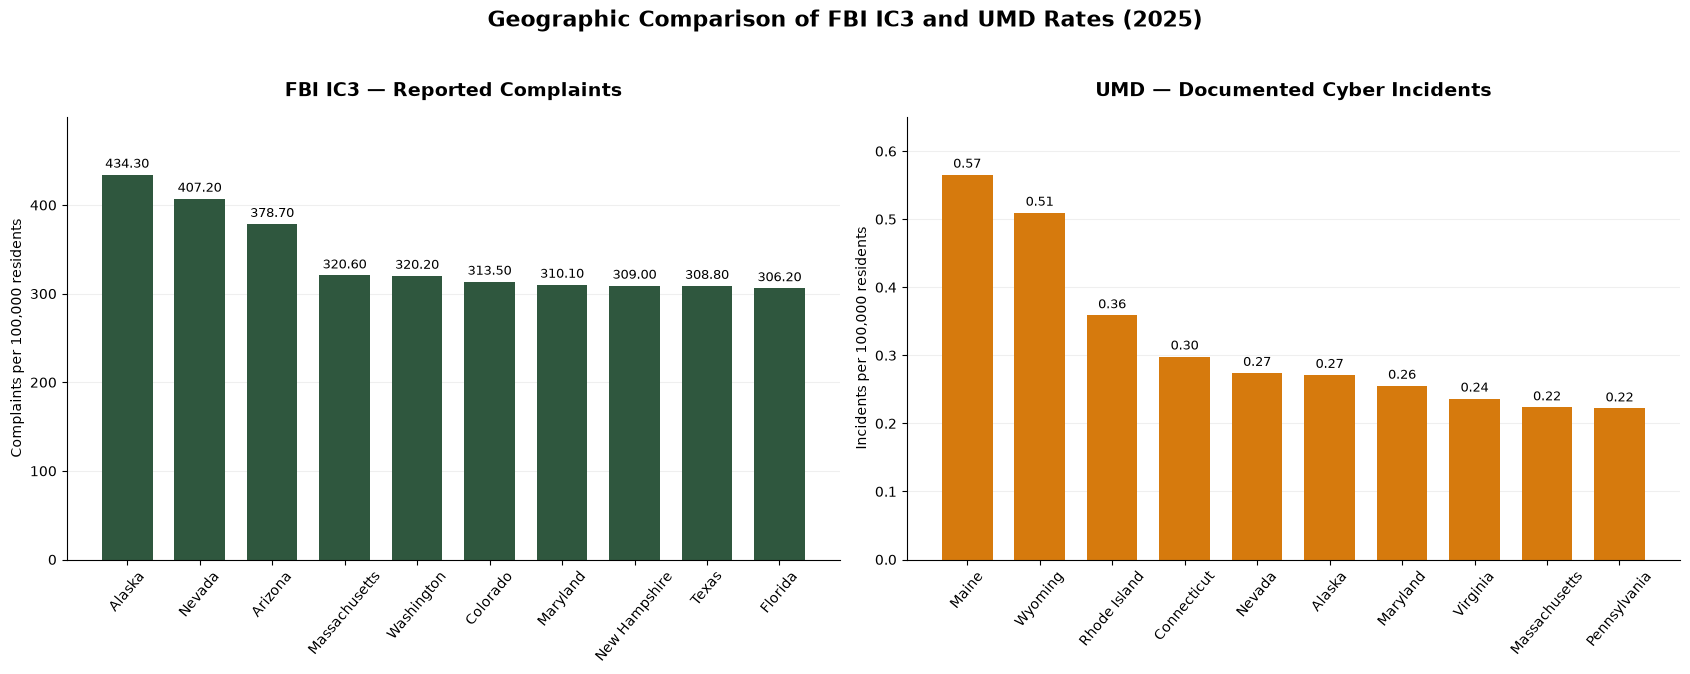

In [35]:
# Top 10 states by population-adjusted rates in FBI IC3 and UMD
top_fbi = comparison_2025.nlargest(
    10, "complaints_per_100k"
)

top_umd = comparison_2025.nlargest(
    10, "incidents_per_100k"
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

plots = [
    (
        top_fbi,
        "complaints_per_100k",
        "FBI IC3 — Reported Complaints",
        "Complaints per 100,000 residents",
        "#2F573E"
    ),
    (
        top_umd,
        "incidents_per_100k",
        "UMD — Documented Cyber Incidents",
        "Incidents per 100,000 residents",
        "#D67A0D"
    )
]

for ax, (data, column, title, ylabel, color) in zip(axes, plots):

    bars = ax.bar(
        data["state"],
        data[column],
        color=color,
        width=0.7
    )

    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            f"{value:.2f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=50)

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

fig.suptitle(
    "Geographic Comparison of FBI IC3 and UMD Rates (2025)",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_10_fbi_umd_geographic_comparison_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



**Key findings**

The geographic distributions of FBI IC3 complaints and UMD publicly documented incidents differ considerably. Alaska, Nevada, Maryland, and Massachusetts appear among the ten states with the highest population-adjusted rates in both datasets.

UMD rates are particularly elevated in several smaller states, including Maine, Wyoming, and Rhode Island. Given the relatively small number of documented UMD incidents, population-adjusted rates may be sensitive to individual events, particularly in states with smaller populations.

These differences highlight the importance of reporting coverage, population size, and statistical stability when comparing the two sources.


#### Absolute Counts Comparison

Absolute counts are shown to complement the population-adjusted rates. This comparison highlights how large states dominate in total complaint and incident counts, while smaller states may stand out more strongly in normalized rates.

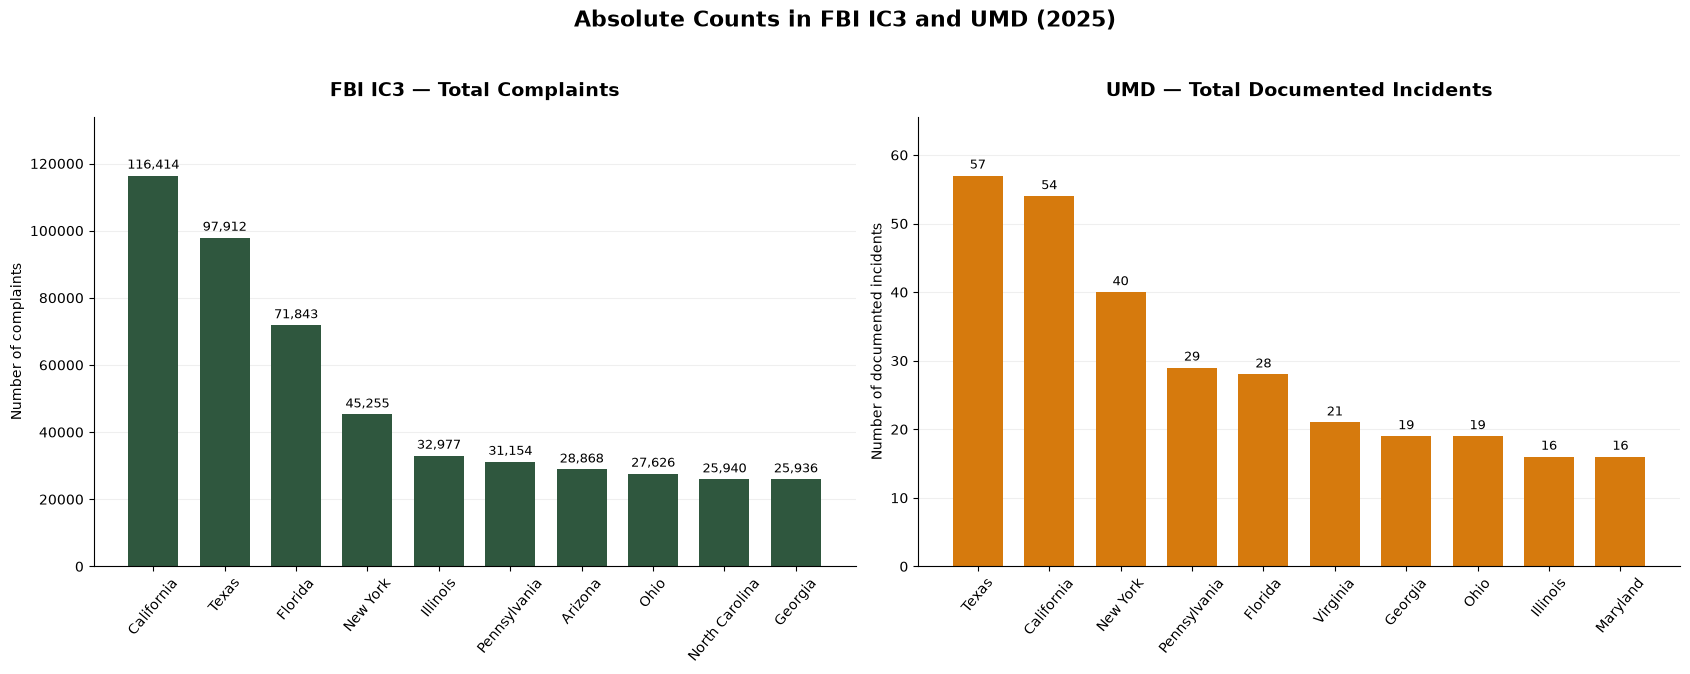

In [36]:
# Top 10 states by absolute counts in FBI IC3 and UMD

top_fbi_abs = comparison_2025.nlargest(
    10, "complaints"
)

top_umd_abs = comparison_2025.nlargest(
    10, "incident_count"
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

plots = [
    (
        top_fbi_abs,
        "complaints",
        "FBI IC3 — Total Complaints",
        "Number of complaints",
        "#2F573E"
    ),
    (
        top_umd_abs,
        "incident_count",
        "UMD — Total Documented Incidents",
        "Number of documented incidents",
        "#D67A0D"
    )
]

for ax, (data, column, title, ylabel, color) in zip(axes, plots):
    bars = ax.bar(
        data["state"],
        data[column],
        color=color,
        width=0.7
    )

    for bar in bars:
        value = bar.get_height()
        ax.annotate(
            f"{value:,.0f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=50)

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.15)

fig.suptitle(
    "Absolute Counts in FBI IC3 and UMD (2025)",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_11_fbi_umd_absolute_counts_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Key findings**

Absolute counts show substantial geographic overlap between FBI IC3 and UMD. Eight of the ten states with the highest counts appear in both rankings. California and Texas are among the leading states in both sources, while Florida ranks third in FBI complaints and fifth in UMD documented incidents.

In contrast, only four states overlap in the top ten rankings based on population-adjusted rates. Smaller states are particularly prominent in the UMD rate-based ranking, where relatively few documented incidents can produce high per-capita values.

These findings demonstrate that the apparent geographic similarity between the two sources depends strongly on whether absolute counts or population-normalized rates are used.



#### 3.6.2 Association Between FBI IC3 and UMD Rates

The association between FBI IC3 complaint rates and UMD documented incident rates is assessed across 50 U.S. states in 2025.

The Shapiro–Wilk test is applied to both variables. Pearson's correlation is selected when neither variable shows a significant deviation from normality; otherwise, Spearman's rank correlation is used. Statistical significance is assessed at α = 0.05.


In [38]:
# FBI IC3 vs. UMD: normality and correlation (2025)
fbi_rate = comparison_2025["complaints_per_100k"]
umd_rate = comparison_2025["incidents_per_100k"]

# Shapiro–Wilk normality tests
w_fbi, p_fbi = shapiro(fbi_rate)
w_umd, p_umd = shapiro(umd_rate)

normality_comparison = pd.DataFrame([
    {
        "Variable": "FBI IC3 complaint rate",
        "Shapiro W": w_fbi,
        "p-value": p_fbi,
        "Normality rejected": p_fbi < 0.05
    },
    {
        "Variable": "UMD incident rate",
        "Shapiro W": w_umd,
        "p-value": p_umd,
        "Normality rejected": p_umd < 0.05
    }
])

display(normality_comparison.round(4))

# Select correlation method
if p_fbi >= 0.05 and p_umd >= 0.05:
    method = "Pearson"
    coefficient, p_value = pearsonr(fbi_rate, umd_rate)
else:
    method = "Spearman"
    coefficient, p_value = spearmanr(fbi_rate, umd_rate)

print(f"\nCorrelation method: {method}")
print(f"Correlation coefficient: {coefficient:.4f}")
print(f"p-value: {p_value:.6f}")
print(f"Statistically significant: {p_value < 0.05}")


,Variable,Shapiro W,p-value,Normality rejected
0,FBI IC3 complaint rate,0.9424,0.0167,True
1,UMD incident rate,0.8455,0.0000,True



Correlation method: Spearman
Correlation coefficient: 0.3380
p-value: 0.016362
Statistically significant: True


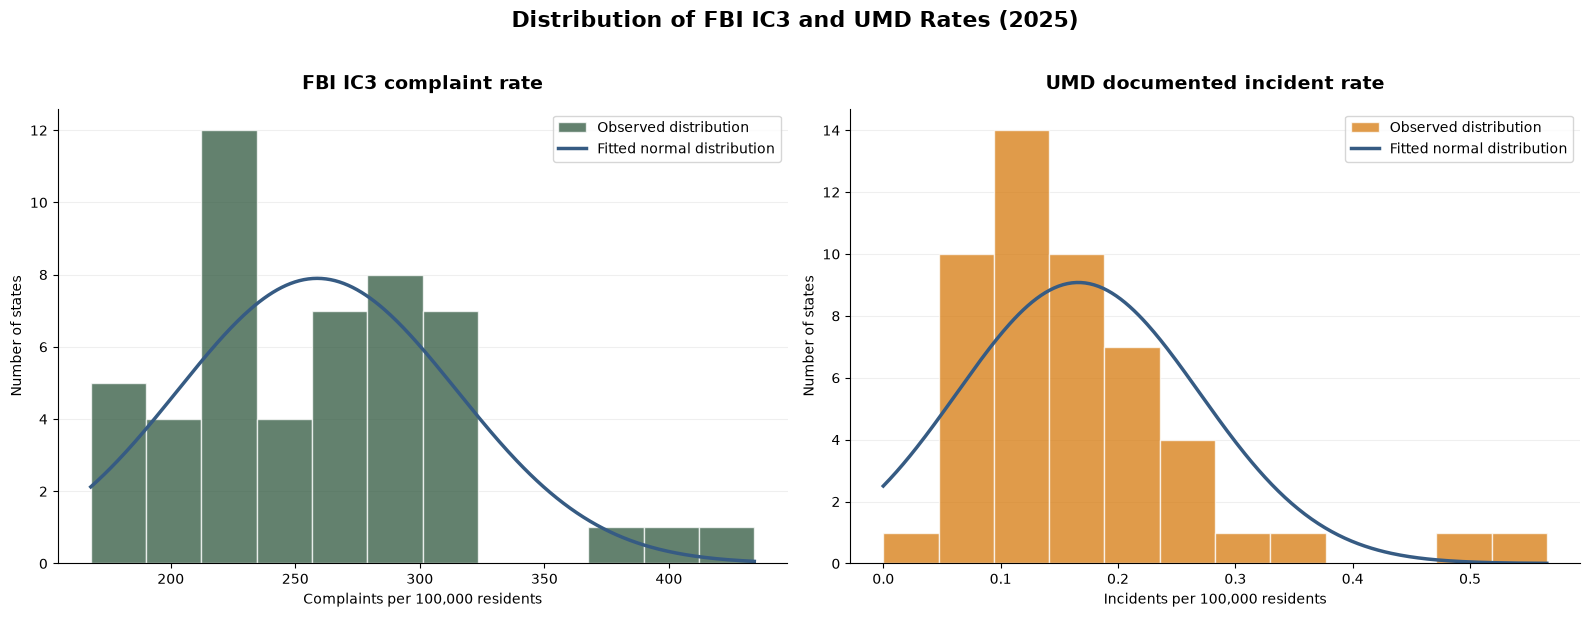

In [39]:
# Distribution assessment: FBI IC3 and UMD rates (2025)
variables = [
    (
        "complaints_per_100k",
        "FBI IC3 complaint rate",
        "Complaints per 100,000 residents",
        "#2F573E"
    ),
    (
        "incidents_per_100k",
        "UMD documented incident rate",
        "Incidents per 100,000 residents",
        "#D67A0D"
    )
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (column, title, xlabel, color) in zip(axes, variables):
    values = comparison_2025[column].dropna().to_numpy()

    counts, edges, _ = ax.hist(
        values,
        bins=12,
        color=color,
        alpha=0.75,
        edgecolor="white",
        label="Observed distribution"
    )

    # Fitted normal distribution
    mu, sigma = norm.fit(values)
    x = np.linspace(values.min(), values.max(), 300)
    bin_width = edges[1] - edges[0]

    expected = norm.pdf(x, mu, sigma) * len(values) * bin_width

    ax.plot(
        x, expected,
        color="#365B83",
        linewidth=2.5,
        label="Fitted normal distribution"
    )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of states")

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()

fig.suptitle(
    "Distribution of FBI IC3 and UMD Rates (2025)",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    STATIC_DIR / "03_12_fbi_umd_rate_distributions_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



#### 3.6.3 Comparison of Economic Associations

Associations between seven economic indicators and FBI IC3 complaint rates are compared with those observed for UMD documented incident rates across the same 50 states in 2025.

Normality is assessed using the Shapiro–Wilk test. Since both cybercrime rate variables deviate significantly from normality, Spearman's rank correlation is applied consistently across both sources. The Benjamini–Hochberg procedure (FDR = 5%) is used separately for each set of seven comparisons.


In [40]:
# Compare economic associations between FBI IC3 and UMD (2025)

outcomes = {
    "FBI IC3": "complaints_per_100k",
    "UMD": "incidents_per_100k"
}

comparison_results = []

for source, outcome in outcomes.items():
    for factor, label in economic_features.items():

        data = comparison_2025[[factor, outcome]].dropna()

        # Normality tests for both variables
        _, p_factor = shapiro(data[factor])
        _, p_outcome = shapiro(data[outcome])

        # Method selection
        if p_factor >= 0.05 and p_outcome >= 0.05:
            method = "Pearson"
            coefficient, p_value = pearsonr(
                data[factor], data[outcome]
            )
        else:
            method = "Spearman"
            coefficient, p_value = spearmanr(
                data[factor], data[outcome]
            )

        comparison_results.append({
            "Source": source,
            "Economic factor": label,
            "Method": method,
            "Coefficient": coefficient,
            "p-value": p_value,
            "Factor Shapiro p": p_factor,
            "Outcome Shapiro p": p_outcome
        })

economic_comparison = pd.DataFrame(comparison_results)

# Benjamini-Hochberg correction within each source
for source in outcomes:

    mask = economic_comparison["Source"] == source
    p_values = economic_comparison.loc[mask, "p-value"].to_numpy()

    m = len(p_values)
    order = np.argsort(p_values)
    ranked_p = p_values[order]

    adjusted = ranked_p * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    original_order = np.empty(m)
    original_order[order] = adjusted

    economic_comparison.loc[mask, "BH-adjusted p"] = original_order

economic_comparison["BH significant"] = (
    economic_comparison["BH-adjusted p"] < 0.05
)

display(
    economic_comparison[
        [
            "Source", "Economic factor", "Method",
            "Coefficient", "p-value",
            "BH-adjusted p", "BH significant",
            "Factor Shapiro p", "Outcome Shapiro p"
        ]
    ].round(4)
)


,Source,Economic factor,Method,Coefficient,p-value,BH-adjusted p,BH significant,Factor Shapiro p,Outcome Shapiro p
0,FBI IC3,GDP per capita,Spearman,0.3785,0.0067,0.0157,True,0.2872,0.0167
1,FBI IC3,Personal income per capita,Spearman,0.4245,0.0021,0.0074,True,0.1295,0.0167
2,FBI IC3,Real GDP growth,Spearman,0.2470,0.0838,0.0978,False,0.2092,0.0167
3,FBI IC3,Unemployment rate,Spearman,0.2789,0.0498,0.0741,False,0.8771,0.0167
4,FBI IC3,Labor force participation,Spearman,0.2754,0.0529,0.0741,False,0.7992,0.0167
5,FBI IC3,Establishment density,Spearman,-0.0587,0.6854,0.6854,False,0.0049,0.0167
6,FBI IC3,Average annual pay,Spearman,0.4857,0.0003,0.0024,True,0.0002,0.0167
7,UMD,GDP per capita,Spearman,0.1565,0.2778,0.4861,False,0.2872,0.0000
8,UMD,Personal income per capita,Spearman,0.3174,0.0247,0.1182,False,0.1295,0.0000
9,UMD,Real GDP growth,Spearman,-0.0461,0.7503,0.9427,False,0.2092,0.0000


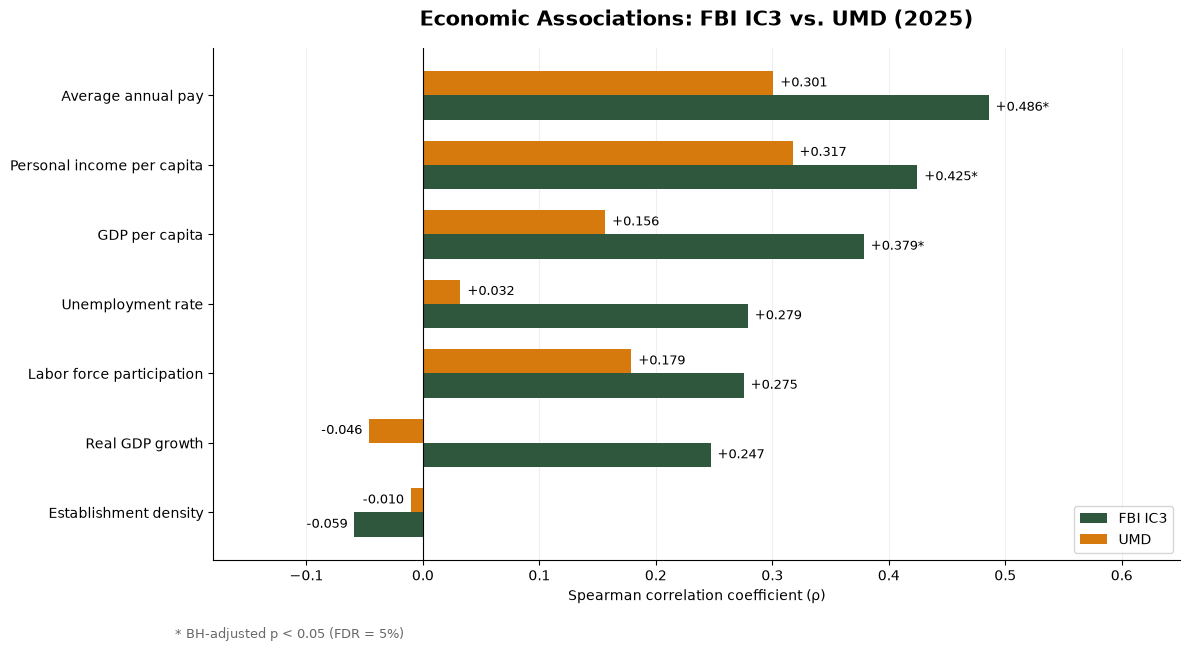

In [41]:
# Compare economic correlations between FBI IC3 and UMD (2025)
factor_order = (
    economic_comparison[economic_comparison["Source"] == "FBI IC3"]
    .sort_values("Coefficient", ascending=True)["Economic factor"]
    .tolist()
)

fbi_results = (
    economic_comparison[economic_comparison["Source"] == "FBI IC3"]
    .set_index("Economic factor")
    .loc[factor_order]
)

umd_results = (
    economic_comparison[economic_comparison["Source"] == "UMD"]
    .set_index("Economic factor")
    .loc[factor_order]
)

y = np.arange(len(factor_order))
height = 0.35

fig, ax = plt.subplots(figsize=(12, 6.5))

bars_fbi = ax.barh(
    y - height / 2,
    fbi_results["Coefficient"],
    height=height,
    color="#2F573E",
    label="FBI IC3"
)

bars_umd = ax.barh(
    y + height / 2,
    umd_results["Coefficient"],
    height=height,
    color="#D67A0D",
    label="UMD"
)

# Coefficient labels and BH significance
for bars, results in [
    (bars_fbi, fbi_results),
    (bars_umd, umd_results)
]:
    for bar, (_, row) in zip(bars, results.iterrows()):
        value = row["Coefficient"]
        marker = "*" if row["BH significant"] else ""

        ax.annotate(
            f"{value:+.3f}{marker}",
            (value, bar.get_y() + bar.get_height() / 2),
            xytext=(5 if value >= 0 else -5, 0),
            textcoords="offset points",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=9
        )

ax.set_yticks(y)
ax.set_yticklabels(factor_order)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.18, 0.65)

ax.set_xlabel("Spearman correlation coefficient (ρ)")
ax.set_title(
    "Economic Associations: FBI IC3 vs. UMD (2025)",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.15, 0.01,
    "* BH-adjusted p < 0.05 (FDR = 5%)",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    STATIC_DIR / "03_13_fbi_umd_economic_correlations_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Key findings**

Average annual pay, personal income per capita, and GDP per capita show positive correlations with cybercrime rates in both FBI IC3 and UMD in 2025. These associations remain statistically significant after BH correction for FBI IC3, but not for UMD.

The UMD dataset contains substantially fewer documented incidents, resulting in potentially less stable state-level rates and reduced ability to detect underlying associations. Therefore, the absence of statistical significance in UMD should not be interpreted as evidence that the relationships do not exist.

The findings indicate partial consistency in the direction of economic associations, while differences in data coverage and reporting mechanisms limit direct comparisons.



## 4. Key Findings and Limitations

The FBI IC3 analysis reveals substantial geographic differences in reported cybercrime, crime composition, and financial losses across U.S. states in 2025.

**Key findings**

- **Geographic differences:** California, Texas, and Florida lead in absolute complaint counts, while smaller states become more prominent when population-adjusted rates are considered.
- **Crime composition:** The distribution of crime types varies across states, particularly for Phishing/Spoofing.
- **Age-related patterns:** Victims aged 60 and over account for the highest reported victim counts and financial losses.
- **Critical infrastructure:** Healthcare and Public Health records the highest combined count of Ransomware and Data Breach complaints among the 16 sectors.
- **Economic associations:** Average annual pay, personal income per capita, and GDP per capita show statistically significant positive correlations with FBI IC3 complaint rates after BH correction.
- **FBI–UMD comparison:** The two sources show partial geographic agreement (Spearman ρ = 0.338, p = 0.0164). Income-related correlations are positive in both datasets, but none remains statistically significant for UMD after BH correction.

**Limitations**

FBI IC3 complaints and UMD publicly documented incidents represent different reporting processes and should not be interpreted as equivalent measurements. The smaller number of documented UMD events may contribute to less stable state-level rates.

The analysis is observational and limited to 2025. Correlations do not establish causation, and differences in statistical significance do not necessarily indicate significant differences between correlation coefficients.

Sector-level FBI statistics cover only Ransomware and Data Breach, without corresponding financial losses or sector-size denominators. Consequently, the findings identify areas for further investigation rather than definitive cybersecurity investment priorities.
